In [1]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt

In [2]:
title = "# Sampling 1: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 1: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

In [91]:
from scipy.stats import norm, uniform, beta, dirichlet, multivariate_normal

In [92]:
def sample(n, prop_dist, target_dist, prop_dist_params, target_dist_params, M):
    samples_generated = 0
    samples_accepted = 0
    samples = []
    while samples_accepted < n:
        x = prop_dist.rvs(*prop_dist_params)
        u = uniform.rvs()
        samples_generated += 1

        if u < target_dist.pdf(x, *target_dist_params) / (M * prop_dist.pdf(x, *prop_dist_params)):
            samples.append(x)
            samples_accepted += 1
    return np.array(samples)


In [93]:
example = 'beta' # beta

if example == 'beta':
    target_dist = beta
    target_dist_params = (2, 5)
    prop_dist = norm
    prop_dist_params = (0.25, 0.4)
    M = 3

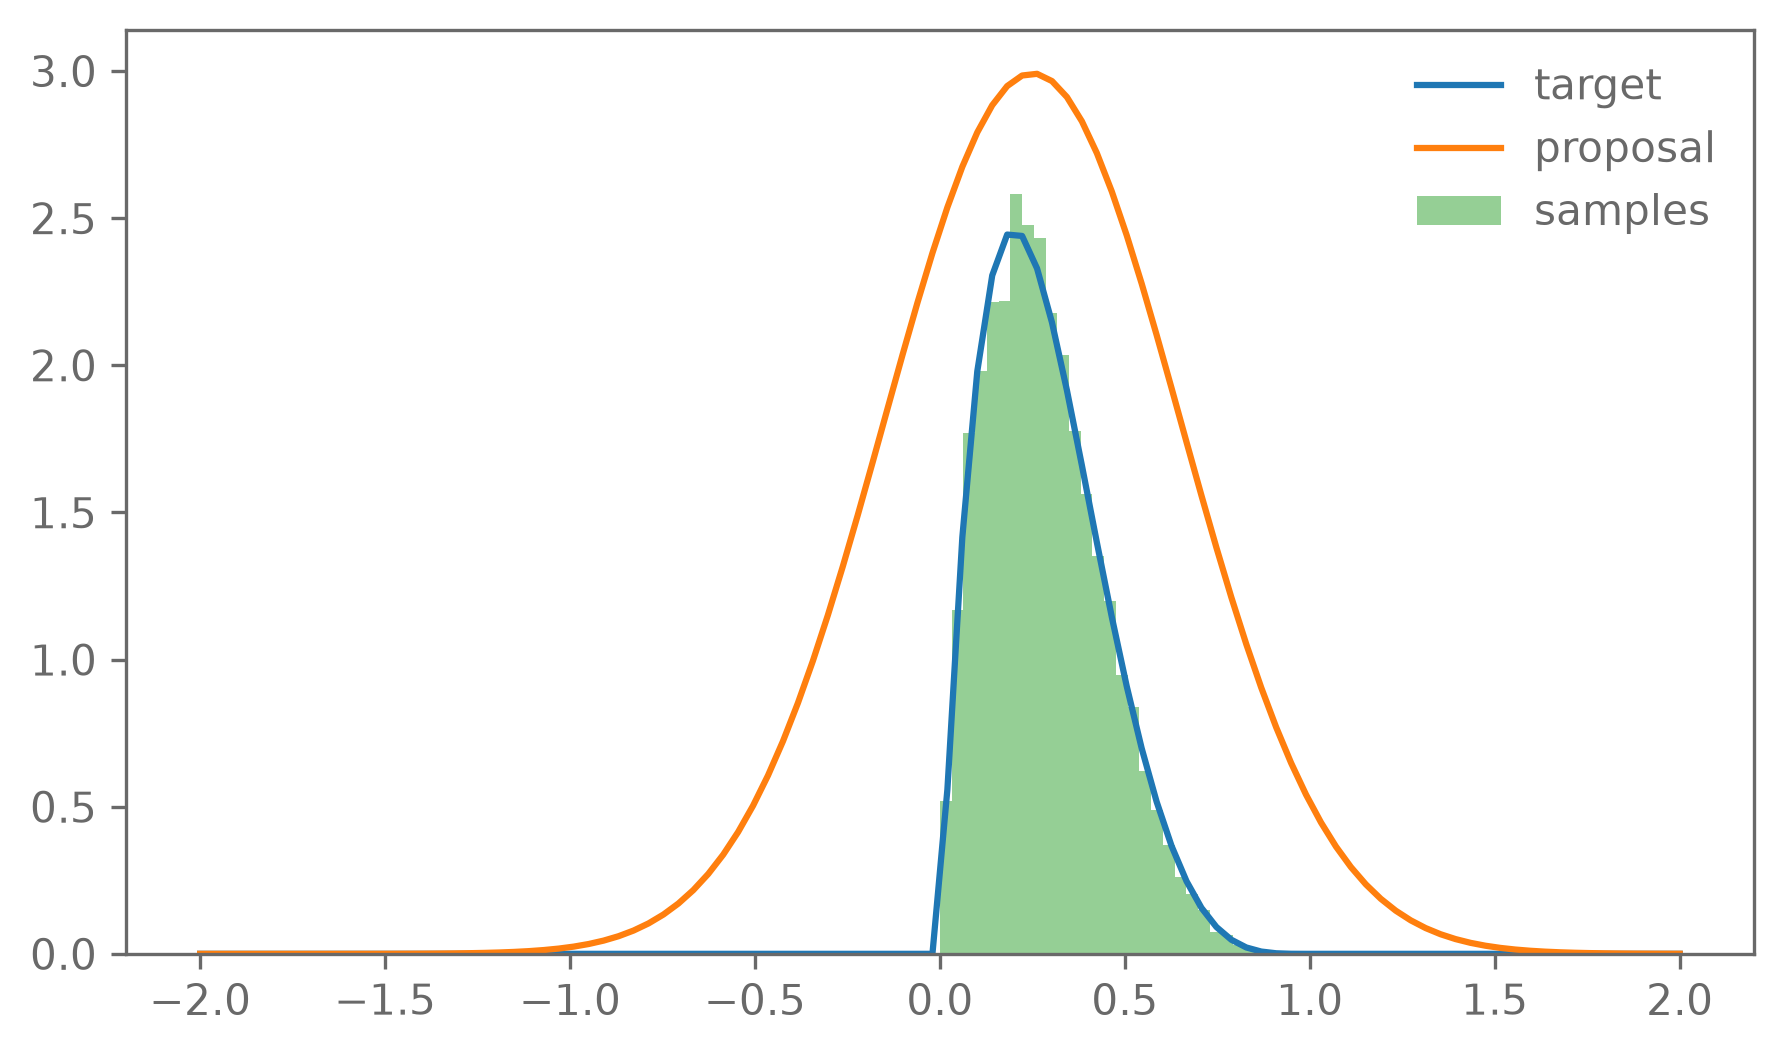

In [94]:
xaxis = np.linspace(-2, 2, 100)
plt.figure()
plt.plot(xaxis, target_dist.pdf(xaxis, *target_dist_params), label="target")
plt.plot(xaxis, M * prop_dist.pdf(xaxis, *prop_dist_params), label="proposal")
plt.hist(sample(10000, prop_dist, target_dist, prop_dist_params, target_dist_params, M), bins=30, density=True, alpha=0.5, label="samples")
plt.legend()
plt.show()

### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

In [115]:
example = 'dirichlet' # beta, dirichlet

class SimplexDirichlet:
    """Dirichlet(alpha) on the 2-simplex, parametrized by its first two coordinates.

    x has shape (..., 2); the third coordinate is 1 - x1 - x2.
    The density is 0 outside the simplex.
    """
    @staticmethod
    def pdf(x, alpha):
        x = np.asarray(x, dtype=float)
        x3 = np.concatenate([x, 1 - x.sum(axis=-1, keepdims=True)], axis=-1)  # (..., 3)
        inside = np.all(x3 > 0, axis=-1)
        out = np.zeros(inside.shape)
        if inside.any():
            # scipy wants components on the first axis: (3, N)
            out[inside] = dirichlet.pdf(x3[inside].T, alpha)
        return out


if example == 'beta':
    target_dist = beta
    target_dist_params = (2, 5)
    prop_dist = norm
    prop_dist_params = (0.25, 0.4)
    M = 3
elif example == 'dirichlet':
    target_dist = SimplexDirichlet
    # target_dist_params = ([1.5, 1.5, 1.5],) #alpha
    target_dist_params = ([5, 5, 5],) #alpha
    prop_dist = multivariate_normal
    prop_dist_params = ([0,0], [[1,0],[0,1]])
    M = 3

In [116]:
def metropolis_hastings(n, prop_dist, target_dist, prop_dist_params, target_dist_params, x0 = None):
    samples = []
    if x0 is None:
        x0 = prop_dist.rvs(*prop_dist_params)

    while len(samples) < n:
        # sample a candidate from the proposal distribution
        x1 = prop_dist.rvs( x0, *prop_dist_params[1:])

        # compute the acceptance probability
        p0 = target_dist.pdf(x0, *target_dist_params)
        p1 = target_dist.pdf(x1, *target_dist_params)
        q01 = prop_dist.pdf(x1, x0, *prop_dist_params[1:])
        q10 = prop_dist.pdf(x0, x1, *prop_dist_params[1:])

        # print(f"x0: {x0}, x1: {x1}, p0: {p0}, p1: {p1}, q01: {q01}, q10: {q10}")

        # b = q10/q01
        # c = p1/p0

        a = p1/p0 * q10/q01 # correct
        # a = p1/p0 * q01/q10

        if a >= 1 or np.random.rand() < a:
            samples.append(x1)
            x0 = x1
        else:
            samples.append(x0)
    
    return np.array(samples)

# metropolis_hastings_samples = metropolis_hastings(100, prop_dist, target_dist, prop_dist_params, target_dist_params)

/var/folders/1k/v7c04t912l1d0d_zx6yw10jw0000gn/T/ipykernel_36301/1550176557.py:21: RuntimeWarning: invalid value encountered in divide
  a = p1/p0 * q10/q01 # correct
/var/folders/1k/v7c04t912l1d0d_zx6yw10jw0000gn/T/ipykernel_36301/1550176557.py:21: RuntimeWarning: divide by zero encountered in divide
  a = p1/p0 * q10/q01 # correct


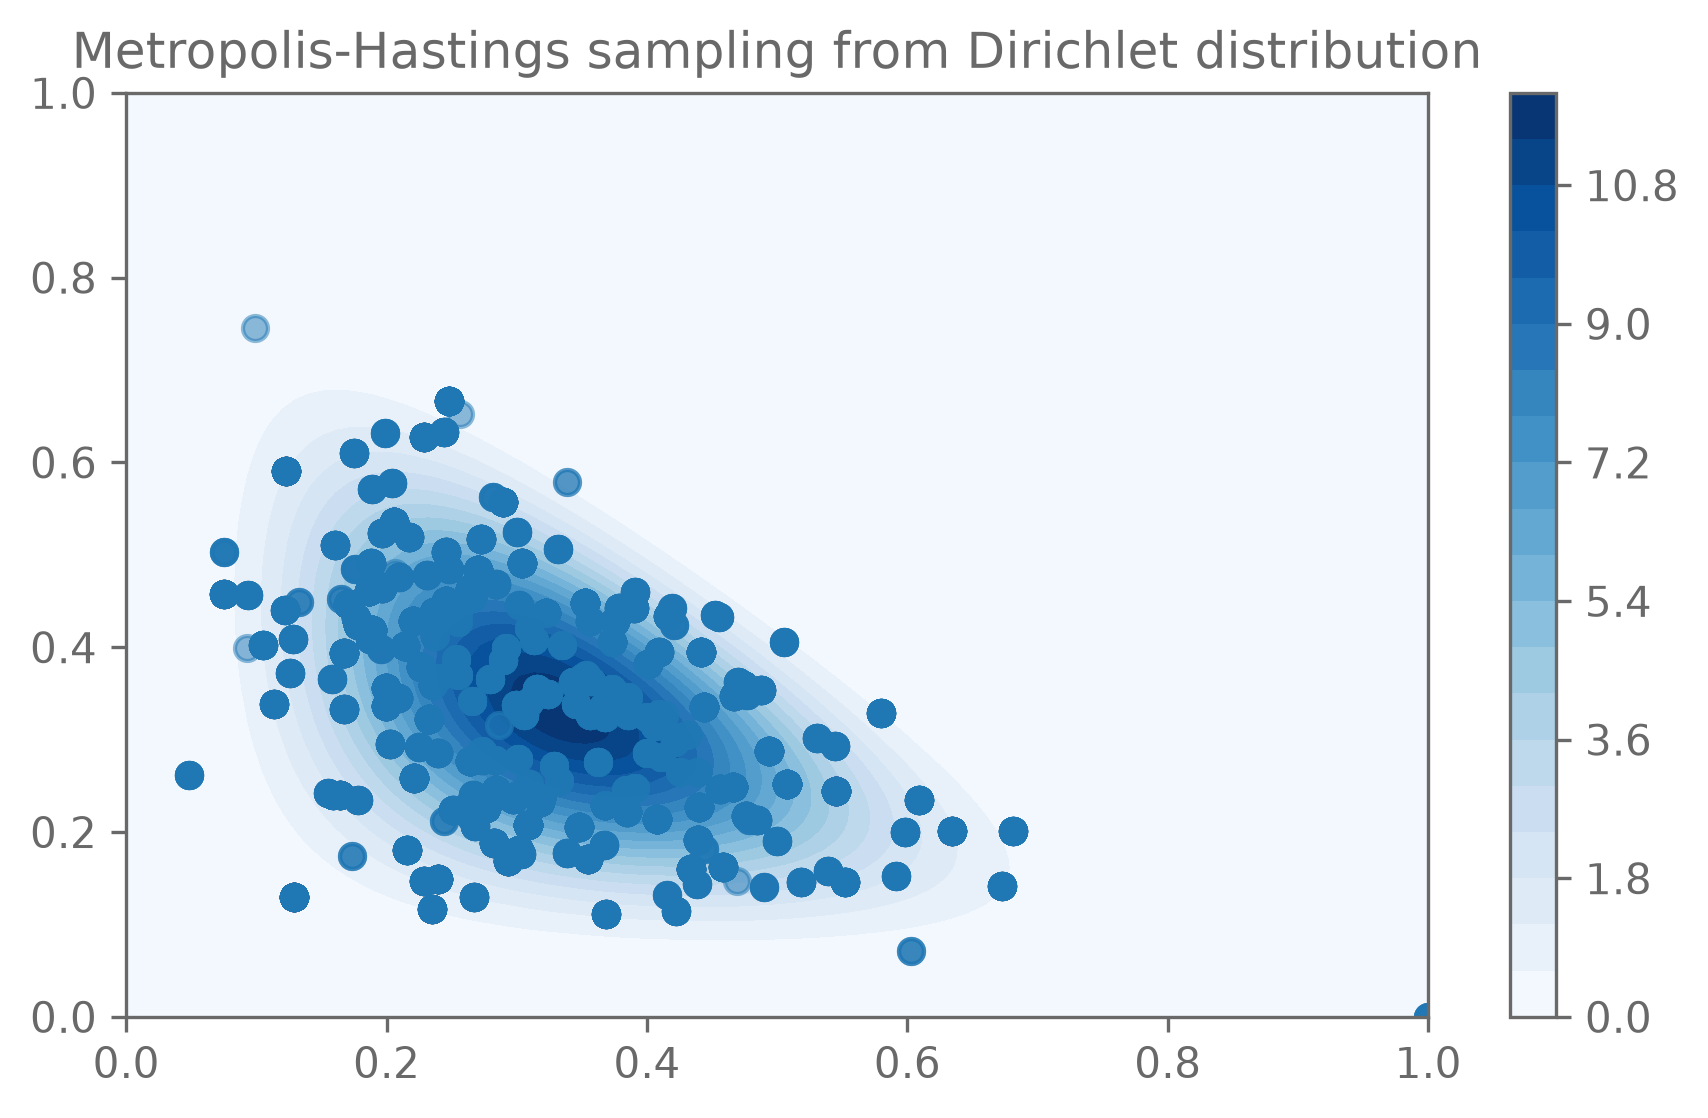

In [122]:
if example == 'beta':
    xaxis = np.linspace(-2, 2, 100)
    plt.figure()
    plt.title("Metropolis-Hastings sampling from Beta distribution")
    plt.plot(xaxis, target_dist.pdf(xaxis, *target_dist_params), label="target")
    plt.plot(xaxis, M * prop_dist.pdf(xaxis, *prop_dist_params), label="proposal")
    plt.hist(metropolis_hastings(10000, prop_dist, target_dist, prop_dist_params, target_dist_params), bins=30, density=True, alpha=0.5, label="samples")
    plt.legend()
    plt.show()

elif example == 'dirichlet':
    # two dimensional example
    xs = np.linspace(0, 1, 100)
    ys = np.linspace(0, 1, 100)
    x0 = np.array([1.0, 0.0])
    X, Y = np.meshgrid(xs, ys)
    Z = target_dist.pdf(np.stack([X, Y], axis=-1), *target_dist_params)
    plt.figure()
    plt.title("Metropolis-Hastings sampling from Dirichlet distribution")
    plt.contourf(X, Y, Z, levels=20, cmap='Blues')
    plt.colorbar()
    plt.scatter(*metropolis_hastings(10000, prop_dist, target_dist, prop_dist_params, target_dist_params, x0=x0).T, alpha=0.5)
    plt.show()


In [ ]:
# Define variances and correlation
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# Create distribution object
bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Sample 1000 points. Do this with your MCMC implementation instead!
samples = bivariate_normal.rvs(size=1000)

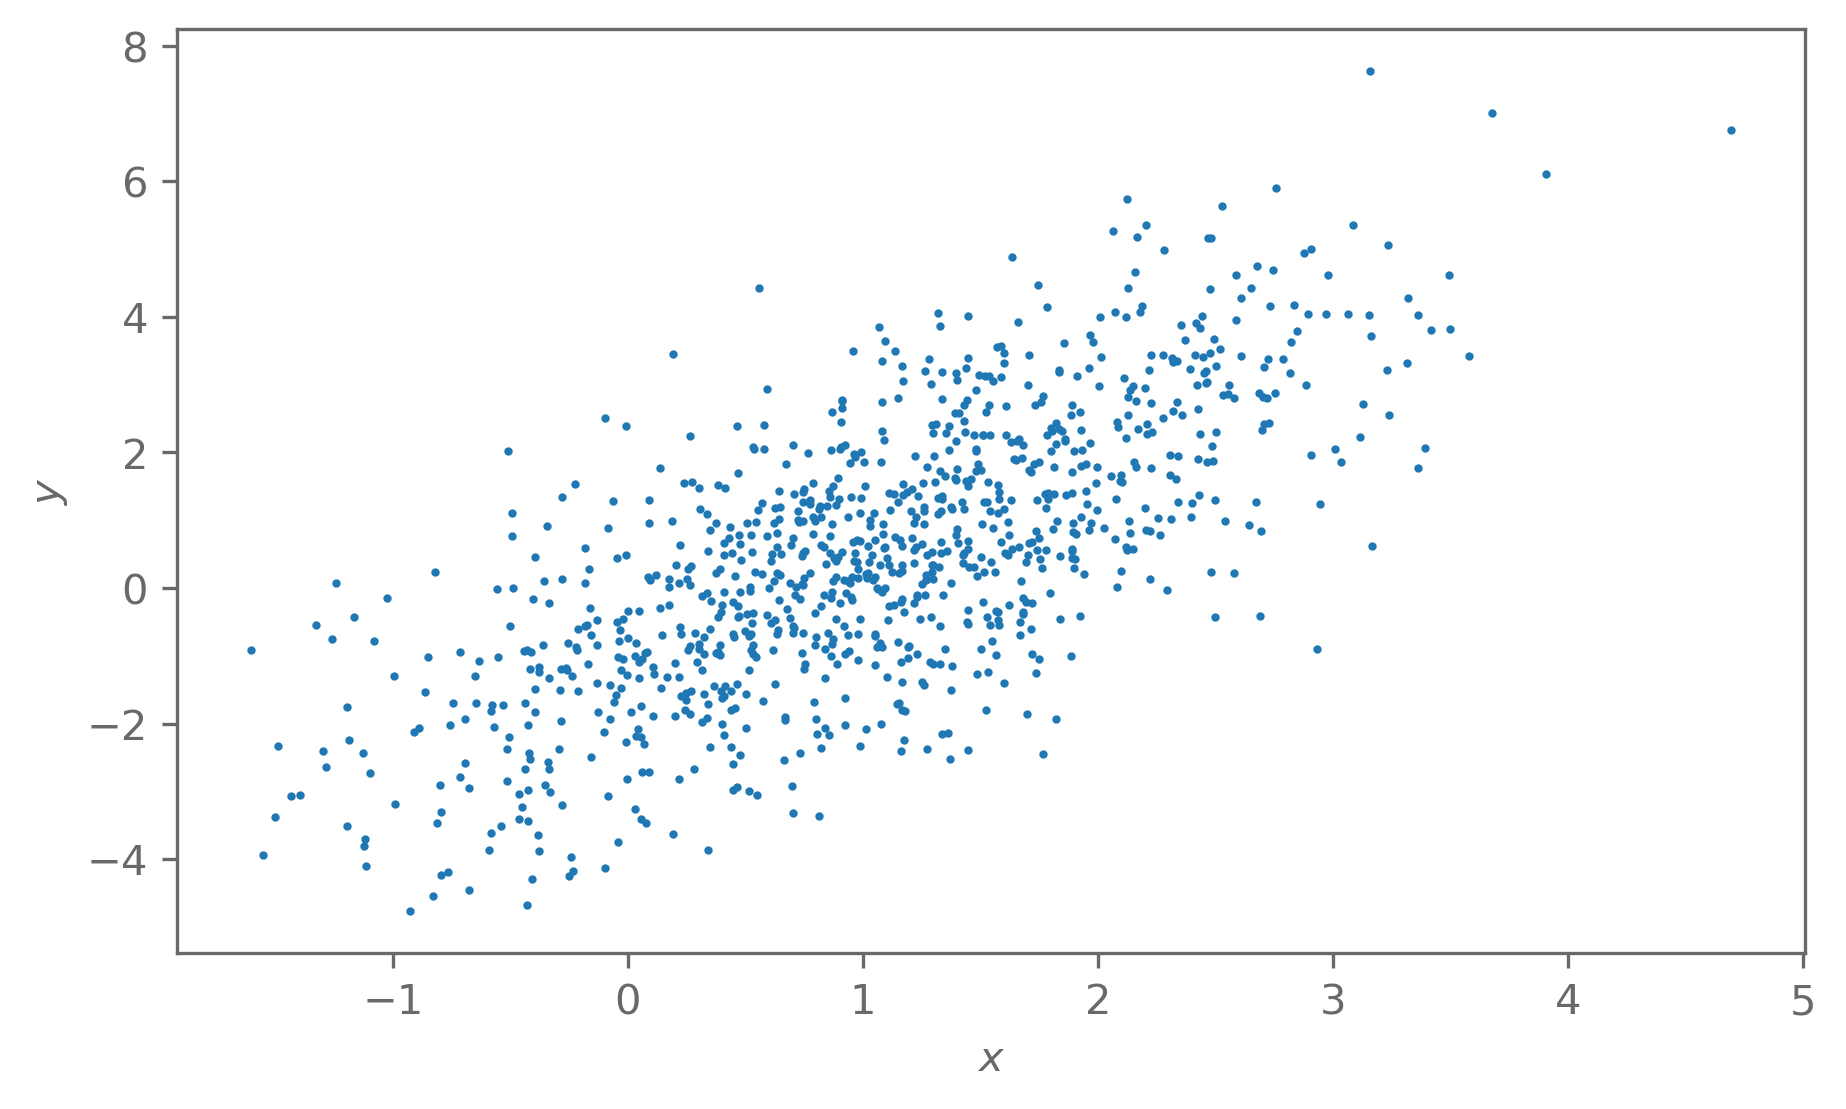

In [ ]:
plt.scatter(*samples.T, s=1)
plt.ylabel("$y$")
plt.xlabel("$x$");